In [1]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config

# Dark solitons in $D_1$

In [2]:
# Create solitons
L_theo = 100
N_theo = 200_001
k = 1/4

pars = {"k":k}

c = np.sqrt(2)/2

# Theretical solitons
w_dark, x_dark = soliton(c, k, soliton_type="dark", L=L_theo, N=N_theo, as_func=True) #c=0

Creating soliton...
Soliton created


In [3]:
x0 = -5
def theo_dark(x, t, x0=x0):
    output = w_dark(x - c*t - x0)
    return output

In [4]:
#path = "test/"
L = 50
N = 100_001

Nt = 2000
tf = 20

w_comp = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_comp.set_w_theo(theo_dark)
w_comp.solve()

Iteration  1  of  2000 . Newton Error:  3.2649549357440423e-11 . Total iteration:  2
Iteration  2  of  2000 . Newton Error:  3.3671812813237234e-11 . Total iteration:  2
Iteration  3  of  2000 . Newton Error:  3.378282191559153e-11 . Total iteration:  2
Iteration  4  of  2000 . Newton Error:  3.420704106542037e-11 . Total iteration:  2
Iteration  5  of  2000 . Newton Error:  3.425200868263291e-11 . Total iteration:  2
Iteration  6  of  2000 . Newton Error:  3.442006124937817e-11 . Total iteration:  2
Iteration  7  of  2000 . Newton Error:  3.443837747715532e-11 . Total iteration:  2
Iteration  8  of  2000 . Newton Error:  3.43267354521715e-11 . Total iteration:  2
Iteration  9  of  2000 . Newton Error:  3.4479490198631685e-11 . Total iteration:  2
Iteration  10  of  2000 . Newton Error:  3.451803646424745e-11 . Total iteration:  2
Iteration  11  of  2000 . Newton Error:  3.446534490610212e-11 . Total iteration:  2
Iteration  12  of  2000 . Newton Error:  3.461099256016967e-11 . Total i

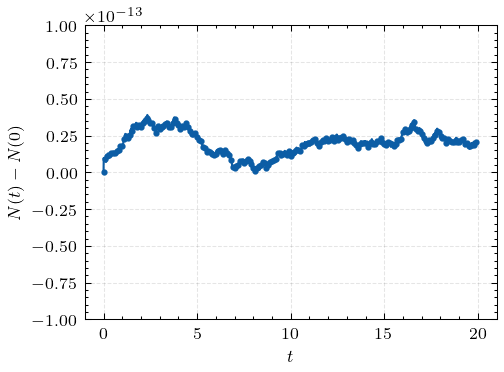

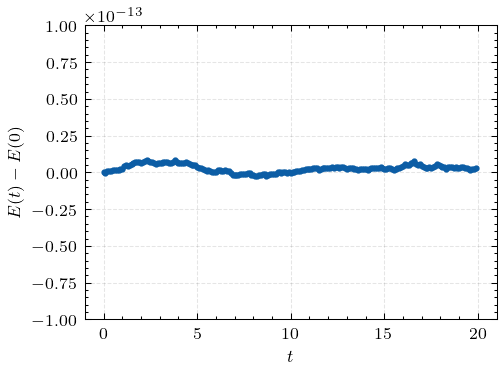

In [5]:
plt.figure()
plt.ylim(-1e-13, 1e-13)
mass_stand = w_comp.get_mass(plot=True, ms=2, markevery=10)

plt.figure()
plt.ylim(-1e-13, 1e-13)
energy_stand = w_comp.get_energy(plot=True, ms=2, markevery=10)

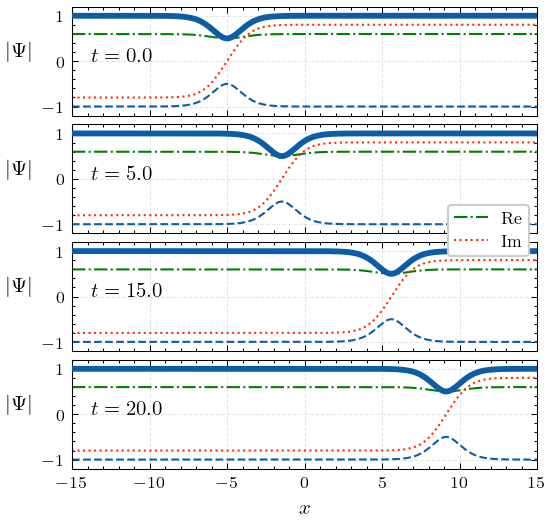

In [6]:
x = w_comp.x
t = w_comp.t
w_plot = w_comp.w
times_to_plot = [0, 5, 15, 20]

plot_snapshots(x, t, w_plot, times_to_plot, figsize=(4, 4), L=15, text_pos=(0.04, 0.50), save_path="Snapshots/DS_D1.pdf") #4, 4

In [7]:
ani = gif_snapshots(
    x,
    t,
    w_plot,
    save_path="gifs/D1.gif",
    n_frames=80,
    fps=15,
    L=15,
    text_pos=(0.04, 0.50)
)

In [9]:
def animate_solution_with_invariants(
    sim,
    save_path,
    N_frames=10,
    fps=15,
    mass=None,
    energy=None,
    theo=False,
    auto_adjust=True,
    L=None
):
    x, t, w = sim.x, sim.t, sim.w

    if mass is None:
        mass = sim.get_mass()
    if energy is None:
        energy = sim.get_energy()

    delta_mass = mass - mass[0]
    delta_energy = energy - energy[0]

    frames = np.arange(0, len(t), N_frames)
    frames = np.unique(np.append(frames, len(t) - 1))

    fig, (ax_sol, ax_inv) = plt.subplots(1, 2, figsize=(6, 3))
    fig.subplots_adjust(wspace=0.1, left=0.10, right=0.97, bottom=0.16)

    # Panel izquierdo: solución
    line_sol, = ax_sol.plot(x, norm(w[0]), "-", label="Simulation", ms=0)

    if theo:
        line_theo, = ax_sol.plot(
            x, norm(sim.w_theo(x, t[0])), "--", label="Theo", alpha=0.9, 
            ms=0, color="C2"
        )
    else:
        line_theo, = ax_sol.plot([], [], "--", alpha=0.9, ms=0, color="C2")

    ax_sol.set_xlabel(r"$x$")
    ax_sol.set_ylabel(r"$|\Psi|^2$", rotation=0, labelpad=15)
    if L is not None:
        ax_sol.set_xlim(-L, L)
    ax_sol.legend()
    title = ax_sol.set_title(rf"$t={t[0]:.2f}$")

    if not auto_adjust:
        ax_sol.set_ylim(norm(w).min() - 0.2, norm(w).max() + 0.2)

    # Panel derecho: invariantes
    line_mass, = ax_inv.plot([], [], label=r"$N(t)-N(0)$", ms=0)
    line_energy, = ax_inv.plot([], [], label=r"$E(t)-E(0)$", ms=0)

    ax_inv.set_xlim(t[0], t[-1])

    max_variation = max(
        np.max(np.abs(delta_mass)),
        np.max(np.abs(delta_energy)),
        1e-15,
    )
    ax_inv.set_ylim(-1.1 * max_variation, 1.1 * max_variation)

    ax_inv.set_xlabel(r"$t$")
    ax_inv.set_ylabel("", rotation=0, labelpad=15)
    ax_inv.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
    ax_inv.legend()

    def update(j):
        sol_j = norm(w[j])
        line_sol.set_data(x, sol_j)

        if auto_adjust:
            ax_sol.set_ylim(sol_j.min() - 0.2, sol_j.max() + 0.2)

        if theo:
            line_theo.set_data(x, norm(sim.w_theo(x, t[j])))

        line_mass.set_data(t[:j + 1], delta_mass[:j + 1])
        line_energy.set_data(t[:j + 1], delta_energy[:j + 1])
        title.set_text(rf"$t={t[j]:.2f}$")

        return line_sol, line_theo, line_mass, line_energy, title

    ani = FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=1000 / fps,
        blit=False,
    )

    ani.save(save_path, writer=PillowWriter(fps=fps))
    plt.close(fig)

    return ani

In [10]:
ani = animate_solution_with_invariants(
    w_comp,
    save_path="gifs/moving_D1_with_invariants.gif",
    N_frames=10,
    fps=15,
    mass=mass_stand,
    energy=energy_stand,
    theo=True,
    L=20
)

# Dark solitons in $D_2$

## Stable

In [11]:
# Create solitons
L_theo = 200
N_theo = 40_001

k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c = c_star + eps

# Theoretical solitons
w_dark_D2, x_dark = soliton(c, k, soliton_type="dark", L=L_theo, N=N_theo, as_func=True) #c=0

Creating soliton...
Soliton created


In [12]:
x0 = -5
def theo_dark_D2(x, t, x0=x0):
    output = w_dark_D2(x - c*t-x0)
    return output

In [13]:
#path = "test/"
N = 20_001
L = 100
Nt = 2000
tf = 40

w_D2 = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_D2.set_w_theo(theo_dark_D2)
w_D2.solve()

Iteration  1  of  2000 . Newton Error:  5.573429615033983e-11 . Total iteration:  2
Iteration  2  of  2000 . Newton Error:  5.4831382138114466e-11 . Total iteration:  2
Iteration  3  of  2000 . Newton Error:  5.536382775260782e-11 . Total iteration:  2
Iteration  4  of  2000 . Newton Error:  5.582999829646295e-11 . Total iteration:  2
Iteration  5  of  2000 . Newton Error:  5.5575341214333595e-11 . Total iteration:  2
Iteration  6  of  2000 . Newton Error:  5.572412218714175e-11 . Total iteration:  2
Iteration  7  of  2000 . Newton Error:  5.6391076188314665e-11 . Total iteration:  2
Iteration  8  of  2000 . Newton Error:  5.6151054591696415e-11 . Total iteration:  2
Iteration  9  of  2000 . Newton Error:  5.611953250167902e-11 . Total iteration:  2
Iteration  10  of  2000 . Newton Error:  5.639132996042396e-11 . Total iteration:  2
Iteration  11  of  2000 . Newton Error:  5.7559505340689727e-11 . Total iteration:  2
Iteration  12  of  2000 . Newton Error:  5.636806027570314e-11 . Tota

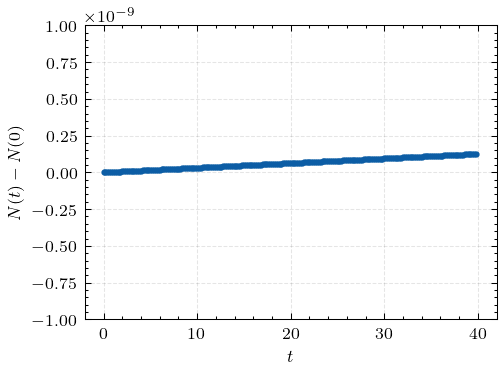

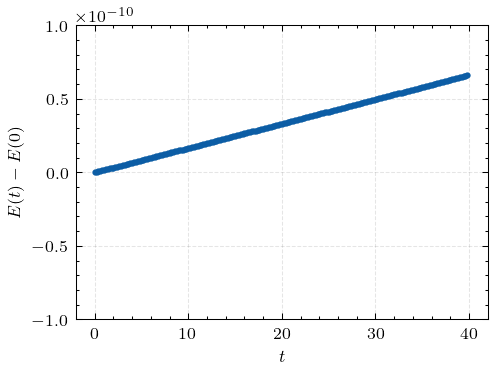

In [14]:
plt.figure()
plt.ylim(-1e-9, 1e-9)
mass_stand = w_D2.get_mass(plot=True, ms=2, markevery=10)

plt.figure()
plt.ylim(-1e-10, 1e-10)
energy_stand = w_D2.get_energy(plot=True, ms=2, markevery=10)

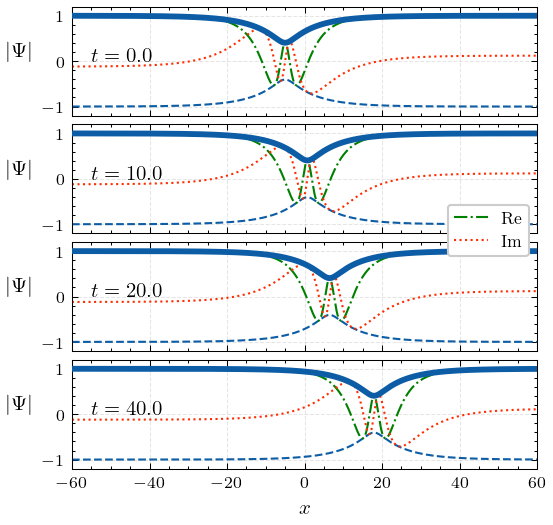

In [15]:
x = w_D2.x
t = w_D2.t
w_plot = w_D2.w
times_to_plot = [0, 10, 20, 40]

plot_snapshots(x, t, w_plot, times_to_plot, figsize=(4, 4), L=60, text_pos=(0.04, 0.50), save_path="Snapshots/DS_D2_st.pdf")

In [29]:
def gif_snapshots(x, t, w, save_path, n_frames=120, fps=20, L=None, text_pos=(0.04, 0.90)):
    frame_ids = np.unique(
        np.linspace(0, len(t) - 1, n_frames, dtype=int)
    )

    # Límites fijos para evitar que el gráfico salte durante la animación
    w_sample = w[frame_ids]
    amplitude = np.abs(w_sample)
    ymin = min(np.real(w_sample).min(), np.imag(w_sample).min(), -amplitude.max()) - 0.2
    ymax = max(np.real(w_sample).max(), np.imag(w_sample).max(), amplitude.max()) + 0.2

    fig, ax = plt.subplots(figsize=(4, 2))#figsize=(6, 4))
    #fig.subplots_adjust(left=0.18)

    wk0 = w[frame_ids[0]]
    amp0 = np.abs(wk0)

    envelope_up, = ax.plot(x, amp0, color="C0", lw=2.8, ms=0)
    envelope_down, = ax.plot(x, -amp0, color="C0", lw=1, ms=0)
    real_line, = ax.plot(x, np.real(wk0), color="green", lw=1, label="Re", ms=0)
    imag_line, = ax.plot(x, np.imag(wk0), color="C3", lw=1, label="Im", ms=0)
    time_text = ax.text(*text_pos, "", transform=ax.transAxes, fontsize=11)

    ax.set_xlabel(r"$x$")
    ax.set_ylabel(r"$|\Psi|$", rotation="horizontal")#, labelpad=14)
    ax.set_ylim(ymin, ymax)
    ax.tick_params(direction="in", top=True, right=True)

    if L is not None:
        ax.set_xlim(-L, L)
    else:
        ax.set_xlim(x[0], x[-1])
    
    ax.legend(fontsize=9, loc="upper right")

    def update(k):
        wk = w[k]
        amp = np.abs(wk)

        envelope_up.set_data(x, amp)
        envelope_down.set_data(x, -amp)
        real_line.set_data(x, np.real(wk))
        imag_line.set_data(x, np.imag(wk))
        time_text.set_text(rf"$t={t[k]:.1f}$")

        return envelope_up, envelope_down, real_line, imag_line, time_text

    ani = FuncAnimation(fig, update, frames=frame_ids, interval=1000 / fps, blit=True)
    ani.save(save_path, writer=PillowWriter(fps=fps))
    plt.close(fig)

    return ani

In [30]:
ani = gif_snapshots(
    x,
    t,
    w_plot,
    save_path="gifs/D2.gif",
    n_frames=80,
    fps=15,
    L=60,
    text_pos=(0.04, 0.50)
)

In [18]:
ani = animate_solution_with_invariants(
    w_D2,
    save_path="gifs/moving_D2_with_invariants.gif",
    N_frames=10,
    fps=15,
    mass=mass_stand,
    energy=energy_stand,
    theo=True,
    L=60
)

## Unstable

In [77]:
# Create solitons
L_theo = 200
N_theo = 200_001

k = -50
pars = {"k":k}
c_0 = np.sqrt(2)/2

P_p_ = lambda c: P_p(c, k)
P_pp_ = lambda c: P_pp(c, k)

c_star, error = newton_1D(c_0, P_p_, P_pp_)

eps = 0.1
c = c_star - eps

# Theoretical solitons
w_dark_D2_uns, x_dark = soliton(c, k, soliton_type="dark", L=L_theo, N=N_theo, as_func=True) #c=0

Creating soliton...
Soliton created


In [89]:
x0 = 0
def theo_dark_D2_uns(x, t, x0=x0):
    output = w_dark_D2_uns(x - c*t-x0)
    return output

In [92]:
#path = "test/"
N = 100_001
L = 100
Nt = 5_000
tf = 5

w_D2_uns = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_D2_uns.set_w_theo(theo_dark_D2_uns)
w_D2_uns.solve()

Iteration  1  of  5000 . Newton Error:  6.054920155469155e-11 . Total iteration:  2
Iteration  2  of  5000 . Newton Error:  6.014346364847182e-11 . Total iteration:  2
Iteration  3  of  5000 . Newton Error:  6.06926464167544e-11 . Total iteration:  2
Iteration  4  of  5000 . Newton Error:  6.058650188917601e-11 . Total iteration:  2
Iteration  5  of  5000 . Newton Error:  6.03912329907086e-11 . Total iteration:  2
Iteration  6  of  5000 . Newton Error:  6.067669531293752e-11 . Total iteration:  2
Iteration  7  of  5000 . Newton Error:  6.072946686549273e-11 . Total iteration:  2
Iteration  8  of  5000 . Newton Error:  6.055922305197328e-11 . Total iteration:  2
Iteration  9  of  5000 . Newton Error:  6.043172106048147e-11 . Total iteration:  2
Iteration  10  of  5000 . Newton Error:  6.05051916125273e-11 . Total iteration:  2
Iteration  11  of  5000 . Newton Error:  6.071795019194982e-11 . Total iteration:  2
Iteration  12  of  5000 . Newton Error:  6.052271876575943e-11 . Total iterat

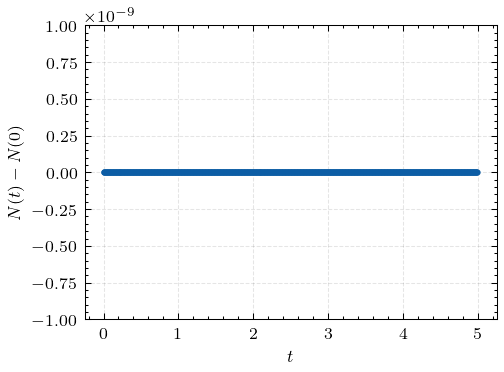

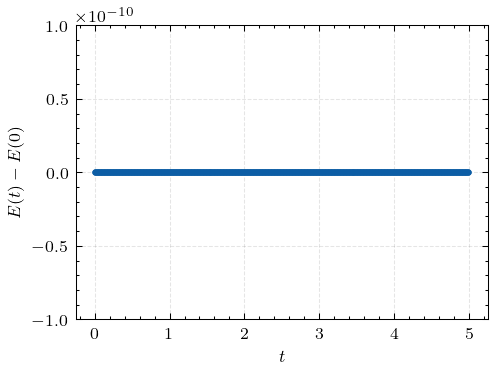

In [95]:
plt.figure()
plt.ylim(-1e-9, 1e-9)
mass_stand = w_D2_uns.get_mass(plot=True, ms=2, markevery=10)

plt.figure()
plt.ylim(-1e-10, 1e-10)
energy_stand = w_D2_uns.get_energy(plot=True, ms=2, markevery=10)

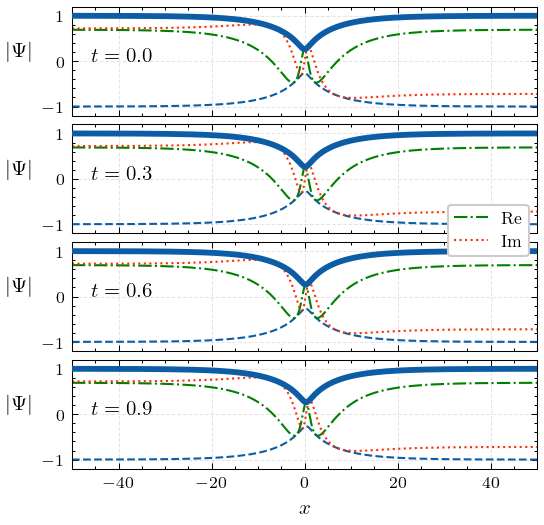

In [112]:
x = w_D2_uns.x
t = w_D2_uns.t
w_plot = w_D2_uns.w
times_to_plot = [0, .3, .6, .9]

plot_snapshots(x, t, w_plot, times_to_plot, figsize=(4, 4), L=50, text_pos=(0.04, 0.50), save_path="Snapshots/DS_D2_uns.pdf")